In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

Libraries imported successfully!


In [6]:
df = pd.read_excel("Online Retail.xlsx")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

df.head()

Dataset loaded successfully!
Dataset shape: (541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [8]:

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[ns]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 33.1+ MB


In [11]:
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [13]:

df["Revenue"] = df["Quantity"] * df["UnitPrice"]


total_revenue = df["Revenue"].sum()

print("Total Sales Revenue:", round(total_revenue, 2))

Total Sales Revenue: 9747747.93


In [15]:
unique_customers = df["CustomerID"].nunique()

print("Total Unique Customers:", unique_customers)

Total Unique Customers: 4372


In [17]:

product_catalog = df[["StockCode", "Description", "UnitPrice"]].drop_duplicates()

print("Total Unique Products:", product_catalog["StockCode"].nunique())

print("\nFirst 10 Products:")
display(product_catalog.head(10))

Total Unique Products: 4070

First 10 Products:


,StockCode,Description,UnitPrice
0,85123A,WHITE HANGING HEART T-LIGHT HOLDER,2.55
1,71053,WHITE METAL LANTERN,3.39
2,84406B,CREAM CUPID HEARTS COAT HANGER,2.75
3,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,3.39
4,84029E,RED WOOLLY HOTTIE WHITE HEART.,3.39
5,22752,SET 7 BABUSHKA NESTING BOXES,7.65
6,21730,GLASS STAR FROSTED T-LIGHT HOLDER,4.25
7,22633,HAND WARMER UNION JACK,1.85
8,22632,HAND WARMER RED POLKA DOT,1.85
9,84879,ASSORTED COLOUR BIRD ORNAMENT,1.69


In [19]:

df["Date"] = df["InvoiceDate"].dt.date

# Calculate daily revenue
daily_sales = df.groupby("Date")["Revenue"].sum()

print("First 10 days of sales:")
print(daily_sales.head(10))

First 10 days of sales:
Date
2010-12-01    58635.56
2010-12-02    46207.28
2010-12-03    45620.46
2010-12-05    31383.95
2010-12-06    53860.18
2010-12-07    45059.05
2010-12-08    44189.84
2010-12-09    52532.13
2010-12-10    57404.91
2010-12-12    17240.92
Name: Revenue, dtype: float64


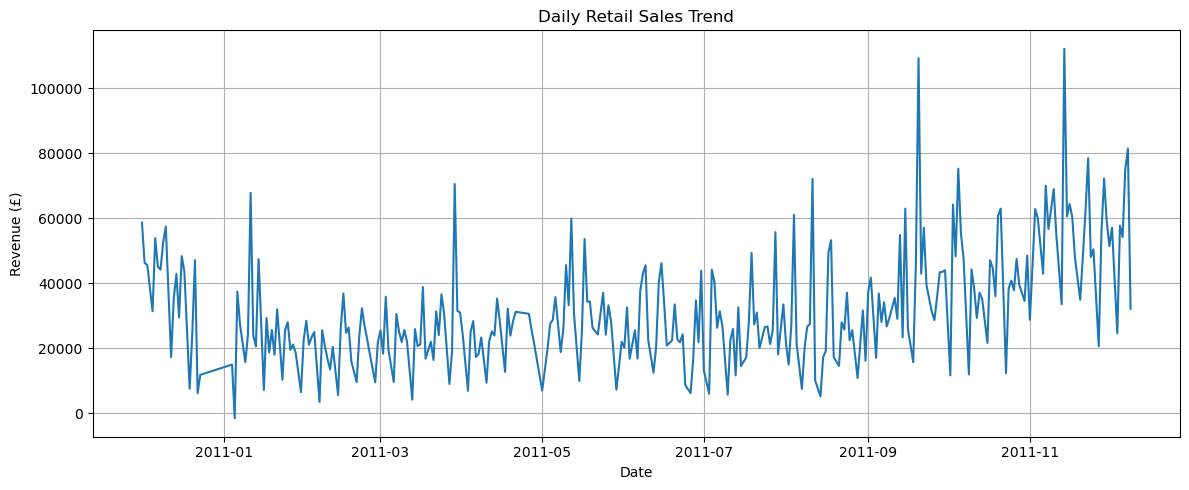

In [21]:
plt.figure(figsize=(12, 5))

daily_sales.plot(kind="line")

plt.title("Daily Retail Sales Trend")
plt.xlabel("Date")
plt.ylabel("Revenue (£)")
plt.grid(True)
plt.tight_layout()
plt.show()

In [23]:

top_products = (
    df.groupby("Description")["Quantity"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

print("Top 10 Products by Quantity Sold:")
print(top_products)

Top 10 Products by Quantity Sold:
Description
WORLD WAR 2 GLIDERS ASSTD DESIGNS     53847
JUMBO BAG RED RETROSPOT               47363
ASSORTED COLOUR BIRD ORNAMENT         36381
POPCORN HOLDER                        36334
PACK OF 72 RETROSPOT CAKE CASES       36039
WHITE HANGING HEART T-LIGHT HOLDER    35317
RABBIT NIGHT LIGHT                    30680
MINI PAINT SET VINTAGE                26437
PACK OF 12 LONDON TISSUES             26315
PACK OF 60 PINK PAISLEY CAKE CASES    24753
Name: Quantity, dtype: int64


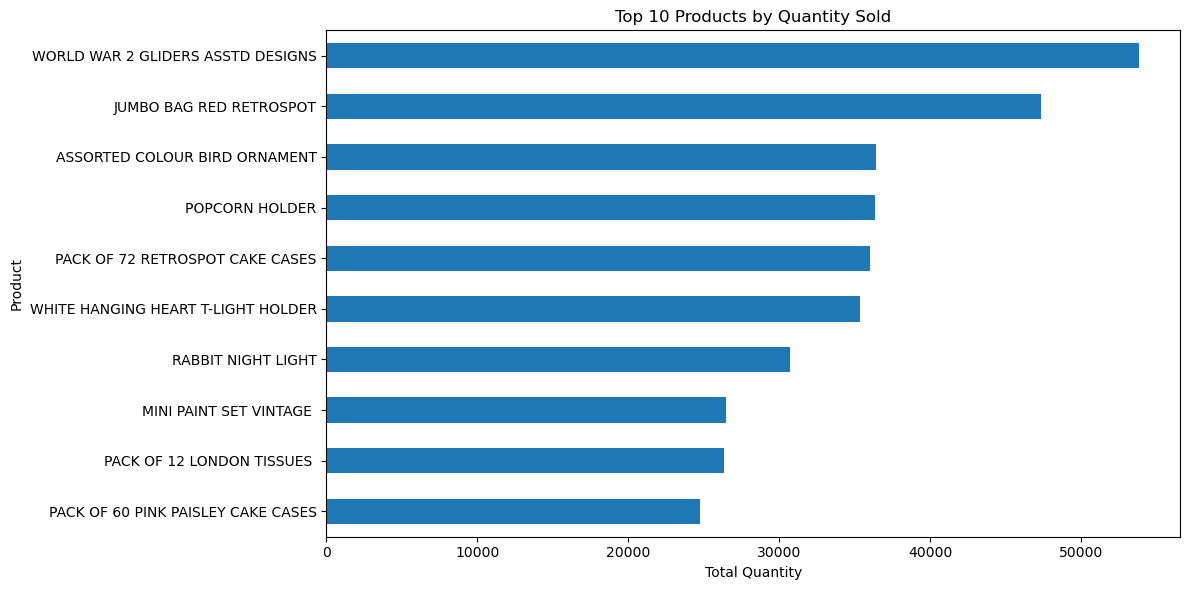

In [25]:
plt.figure(figsize=(12, 6))

top_products.sort_values().plot(kind="barh")

plt.title("Top 10 Products by Quantity Sold")
plt.xlabel("Total Quantity")
plt.ylabel("Product")
plt.tight_layout()
plt.show()

In [27]:

product_revenue = (
    df.groupby("Description")["Revenue"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

print("Top 10 Products by Revenue:")
print(product_revenue.round(2))

Top 10 Products by Revenue:
Description
DOTCOM POSTAGE                        206245.48
REGENCY CAKESTAND 3 TIER              164762.19
WHITE HANGING HEART T-LIGHT HOLDER     99668.47
PARTY BUNTING                          98302.98
JUMBO BAG RED RETROSPOT                92356.03
RABBIT NIGHT LIGHT                     66756.59
POSTAGE                                66230.64
PAPER CHAIN KIT 50'S CHRISTMAS         63791.94
ASSORTED COLOUR BIRD ORNAMENT          58959.73
CHILLI LIGHTS                          53768.06
Name: Revenue, dtype: float64


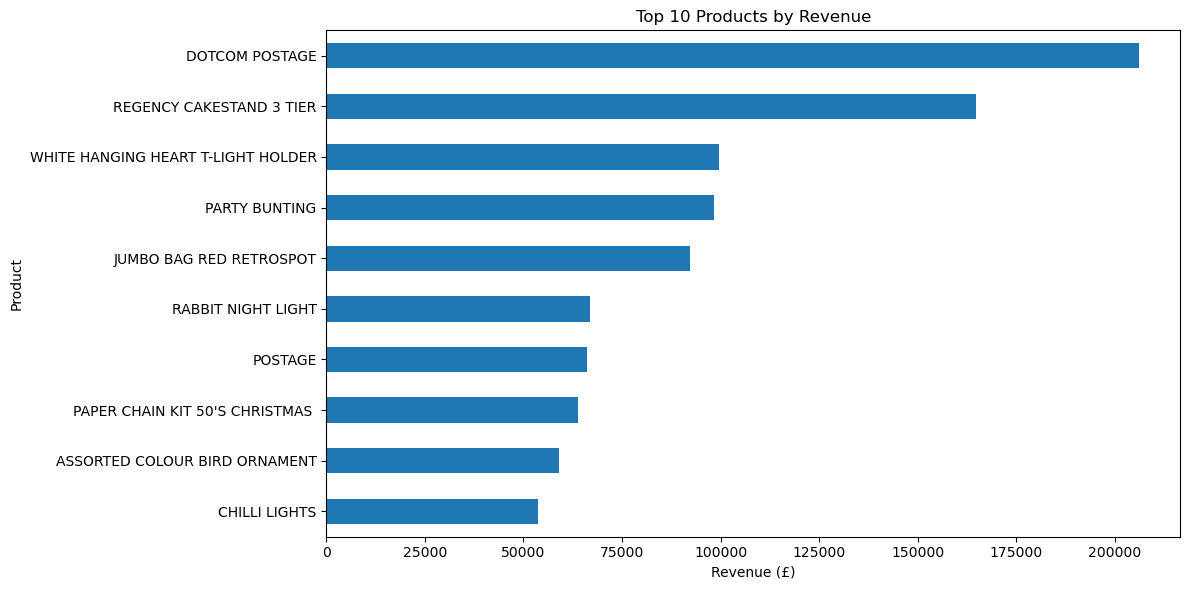

In [29]:
plt.figure(figsize=(12, 6))

product_revenue.sort_values().plot(kind="barh")

plt.title("Top 10 Products by Revenue")
plt.xlabel("Revenue (£)")
plt.ylabel("Product")
plt.tight_layout()
plt.show()

In [31]:
sales_df = df[
    (~df["InvoiceNo"].astype(str).str.startswith("C")) &
    (df["Quantity"] > 0) &
    (df["UnitPrice"] > 0) &
    (df["Description"].notna())
].copy()

sales_df["Revenue"] = sales_df["Quantity"] * sales_df["UnitPrice"]

print("Original dataset shape:", df.shape)
print("Cleaned sales dataset shape:", sales_df.shape)
print("Missing values in cleaned data:")
print(sales_df.isnull().sum())

Original dataset shape: (541909, 10)
Cleaned sales dataset shape: (530104, 10)
Missing values in cleaned data:
InvoiceNo           0
StockCode           0
Description         0
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     132220
Country             0
Revenue             0
Date                0
dtype: int64


In [33]:
customer_spending = (
    sales_df.dropna(subset=["CustomerID"])
    .groupby("CustomerID")["Revenue"]
    .sum()
    .sort_values(ascending=False)
)

print("Top 10 Highest-Spending Customers:")
print(customer_spending.head(10).round(2))

Top 10 Highest-Spending Customers:
CustomerID
14646.0    280206.02
18102.0    259657.30
17450.0    194550.79
16446.0    168472.50
14911.0    143825.06
12415.0    124914.53
14156.0    117379.63
17511.0     91062.38
16029.0     81024.84
12346.0     77183.60
Name: Revenue, dtype: float64


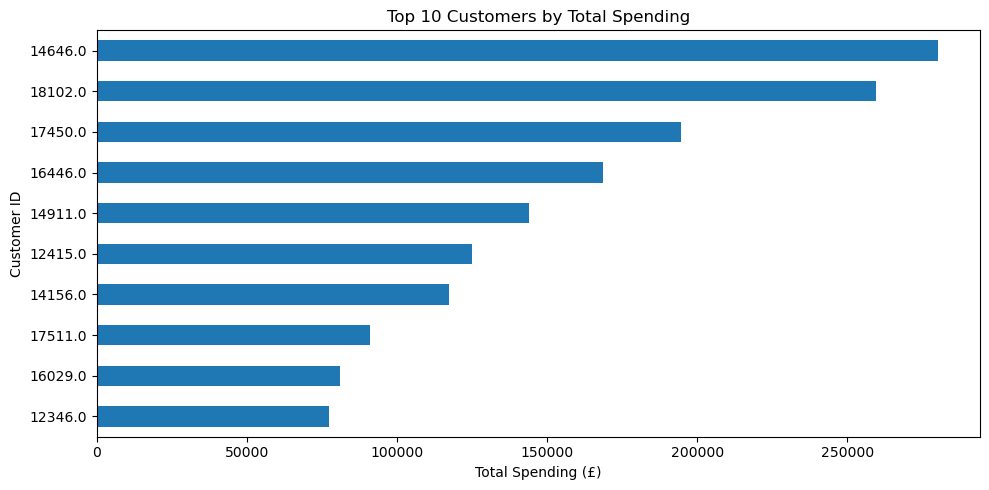

In [35]:
top_customers = customer_spending.head(10)

plt.figure(figsize=(10, 5))
top_customers.sort_values().plot(kind="barh")

plt.title("Top 10 Customers by Total Spending")
plt.xlabel("Total Spending (£)")
plt.ylabel("Customer ID")
plt.tight_layout()
plt.show()

In [37]:
sales_df["Month"] = sales_df["InvoiceDate"].dt.to_period("M")

monthly_sales = sales_df.groupby("Month")["Revenue"].sum()

print("Monthly Sales Revenue:")
print(monthly_sales.round(2))

Monthly Sales Revenue:
Month
2010-12     823746.14
2011-01     691364.56
2011-02     523631.89
2011-03     717639.36
2011-04     537808.62
2011-05     770536.02
2011-06     761739.90
2011-07     719221.19
2011-08     759138.38
2011-09    1058590.17
2011-10    1154979.30
2011-11    1509496.33
2011-12     638792.68
Freq: M, Name: Revenue, dtype: float64


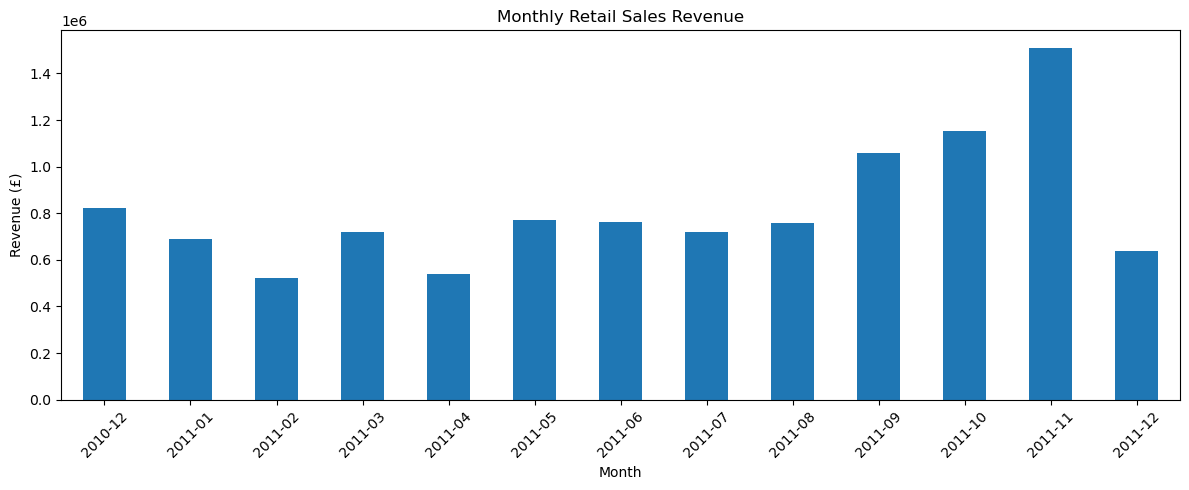

In [39]:
plt.figure(figsize=(12, 5))

monthly_sales.plot(kind="bar")

plt.title("Monthly Retail Sales Revenue")
plt.xlabel("Month")
plt.ylabel("Revenue (£)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [41]:
best_month = monthly_sales.idxmax()
best_revenue = monthly_sales.max()

worst_month = monthly_sales.idxmin()
lowest_revenue = monthly_sales.min()

print("Best Sales Month:", best_month)
print("Highest Revenue: £", round(best_revenue, 2))

print("\nLowest Sales Month:", worst_month)
print("Lowest Revenue: £", round(lowest_revenue, 2))

Best Sales Month: 2011-11
Highest Revenue: £ 1509496.33

Lowest Sales Month: 2011-02
Lowest Revenue: £ 523631.89


In [43]:

low_limit = customer_spending.quantile(0.25)
high_limit = customer_spending.quantile(0.75)

# Classify customers
def segment_customer(spending):
    if spending <= low_limit:
        return "Low Value"
    elif spending <= high_limit:
        return "Medium Value"
    else:
        return "High Value"

customer_segments = customer_spending.apply(segment_customer)

print("Customer Segmentation:")
print(customer_segments.value_counts())

print("\nAverage Spending by Segment:")
print(
    customer_spending.groupby(customer_segments)
    .mean()
    .round(2)
)

Customer Segmentation:
Revenue
Medium Value    2168
High Value      1085
Low Value       1085
Name: count, dtype: int64

Average Spending by Segment:
Revenue
High Value      6499.12
Low Value        179.21
Medium Value     768.18
Name: Revenue, dtype: float64


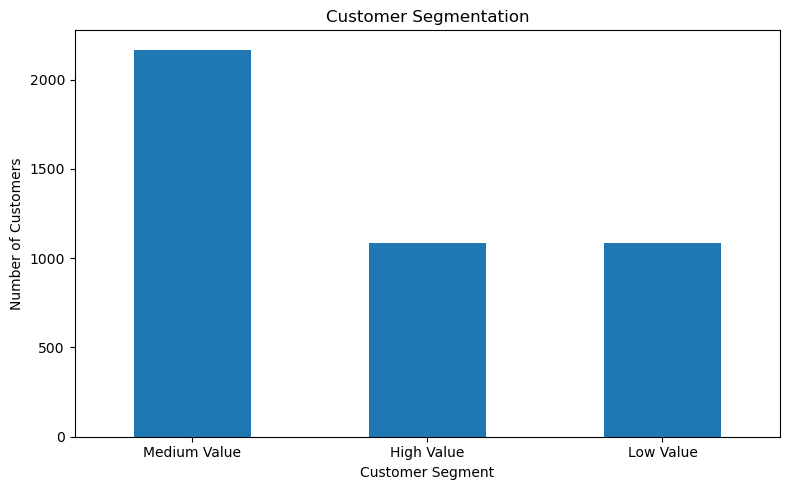

In [45]:
segment_counts = customer_segments.value_counts()

plt.figure(figsize=(8, 5))
segment_counts.plot(kind="bar")

plt.title("Customer Segmentation")
plt.xlabel("Customer Segment")
plt.ylabel("Number of Customers")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [47]:
country_sales = (
    sales_df.groupby("Country")["Revenue"]
    .sum()
    .sort_values(ascending=False)
)

print("Top 10 Countries by Sales Revenue:")
print(country_sales.head(10).round(2))

Top 10 Countries by Sales Revenue:
Country
United Kingdom    9025222.08
Netherlands        285446.34
EIRE               283453.96
Germany            228867.14
France             209715.11
Australia          138521.31
Spain               61577.11
Switzerland         57089.90
Belgium             41196.34
Sweden              38378.33
Name: Revenue, dtype: float64


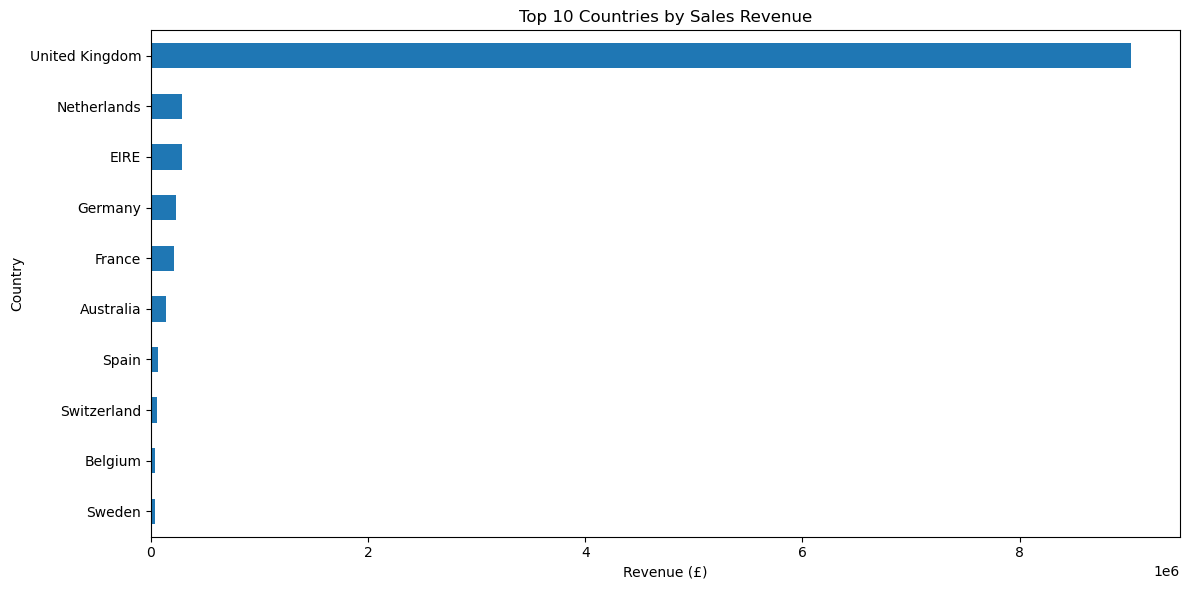

In [49]:
top_countries = country_sales.head(10)

plt.figure(figsize=(12, 6))
top_countries.sort_values().plot(kind="barh")

plt.title("Top 10 Countries by Sales Revenue")
plt.xlabel("Revenue (£)")
plt.ylabel("Country")
plt.tight_layout()
plt.show()

In [51]:
sales_df["DayOfWeek"] = sales_df["InvoiceDate"].dt.day_name()

weekday_sales = (
    sales_df.groupby("DayOfWeek")["Revenue"]
    .sum()
)

day_order = [
    "Monday", "Tuesday", "Wednesday",
    "Thursday", "Friday", "Saturday", "Sunday"
]

weekday_sales = weekday_sales.reindex(day_order)

print("Sales Revenue by Day of the Week:")
print(weekday_sales.round(2))

Sales Revenue by Day of the Week:
DayOfWeek
Monday       1779575.04
Tuesday      2178632.61
Wednesday    1851147.81
Thursday     2203161.24
Friday       1840340.23
Saturday            NaN
Sunday        813827.61
Name: Revenue, dtype: float64


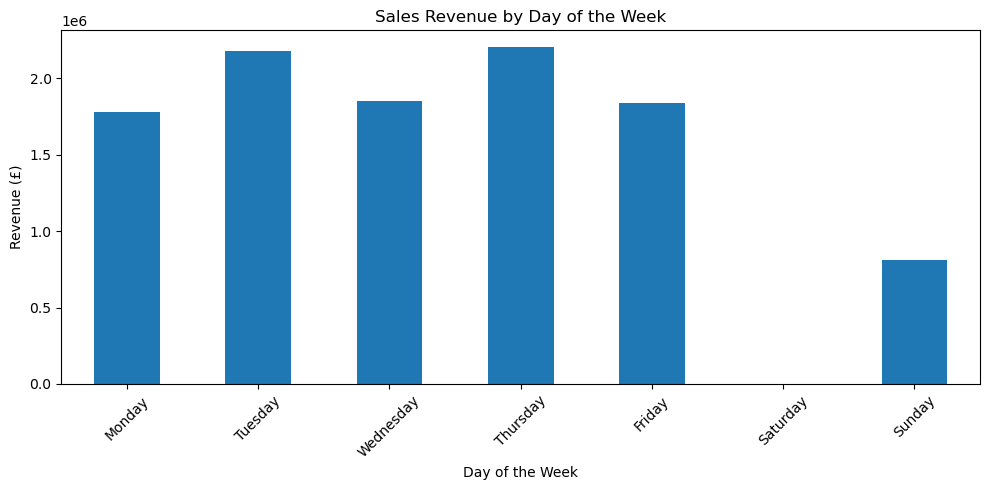

In [53]:
weekday_sales_chart = weekday_sales.fillna(0)

plt.figure(figsize=(10, 5))
weekday_sales_chart.plot(kind="bar")

plt.title("Sales Revenue by Day of the Week")
plt.xlabel("Day of the Week")
plt.ylabel("Revenue (£)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

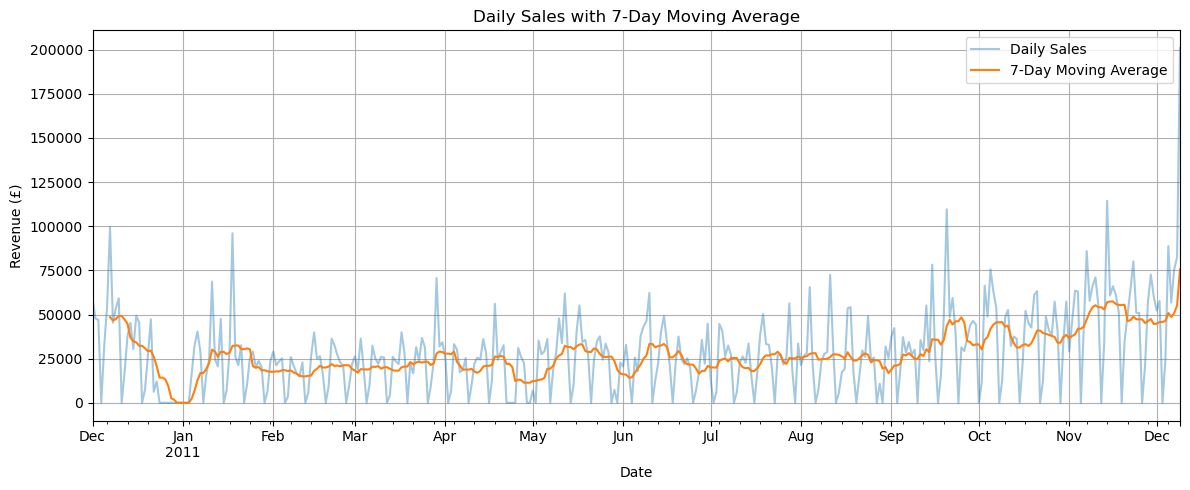

In [55]:
daily_sales = sales_df.groupby(
    sales_df["InvoiceDate"].dt.date
)["Revenue"].sum()

daily_sales.index = pd.to_datetime(daily_sales.index)

# Fill missing calendar dates with zero sales
daily_sales = daily_sales.asfreq("D", fill_value=0)

# Calculate the 7-day moving average
moving_average = daily_sales.rolling(window=7).mean()

plt.figure(figsize=(12, 5))
daily_sales.plot(alpha=0.4, label="Daily Sales")
moving_average.plot(label="7-Day Moving Average")

plt.title("Daily Sales with 7-Day Moving Average")
plt.xlabel("Date")
plt.ylabel("Revenue (£)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [57]:
product_frequency = (
    sales_df.groupby("Description")["InvoiceNo"]
    .nunique()
    .sort_values(ascending=False)
    .head(10)
)

print("Top 10 Most Frequently Purchased Products:")
print(product_frequency)

Top 10 Most Frequently Purchased Products:
Description
WHITE HANGING HEART T-LIGHT HOLDER    2256
JUMBO BAG RED RETROSPOT               2089
REGENCY CAKESTAND 3 TIER              1988
PARTY BUNTING                         1685
LUNCH BAG RED RETROSPOT               1564
ASSORTED COLOUR BIRD ORNAMENT         1455
SET OF 3 CAKE TINS PANTRY DESIGN      1385
PACK OF 72 RETROSPOT CAKE CASES       1320
LUNCH BAG  BLACK SKULL.               1273
NATURAL SLATE HEART CHALKBOARD        1249
Name: InvoiceNo, dtype: int64


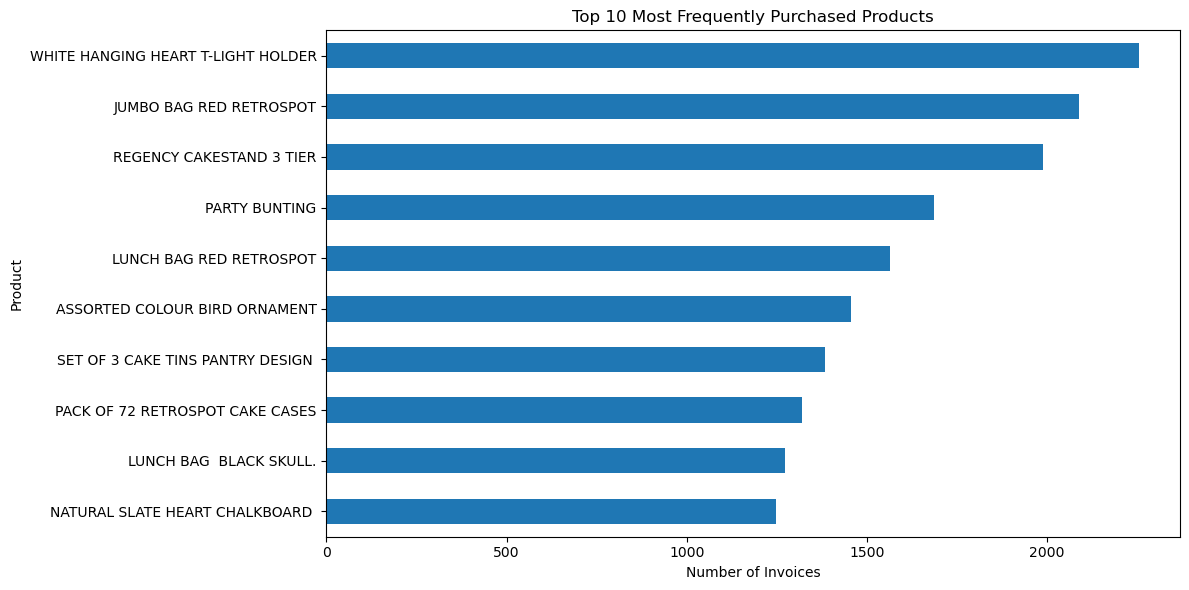

In [59]:
plt.figure(figsize=(12, 6))

product_frequency.sort_values().plot(kind="barh")

plt.title("Top 10 Most Frequently Purchased Products")
plt.xlabel("Number of Invoices")
plt.ylabel("Product")
plt.tight_layout()
plt.show()

In [61]:
country_quantity = (
    sales_df.groupby("Country")["Quantity"]
    .sum()
    .sort_values(ascending=False)
)

print("Top 10 Countries by Quantity Sold:")
print(country_quantity.head(10))

Top 10 Countries by Quantity Sold:
Country
United Kingdom    4662390
Netherlands        200361
EIRE               147173
Germany            119261
France             112103
Australia           83901
Sweden              36083
Switzerland         30629
Spain               27940
Japan               26016
Name: Quantity, dtype: int64


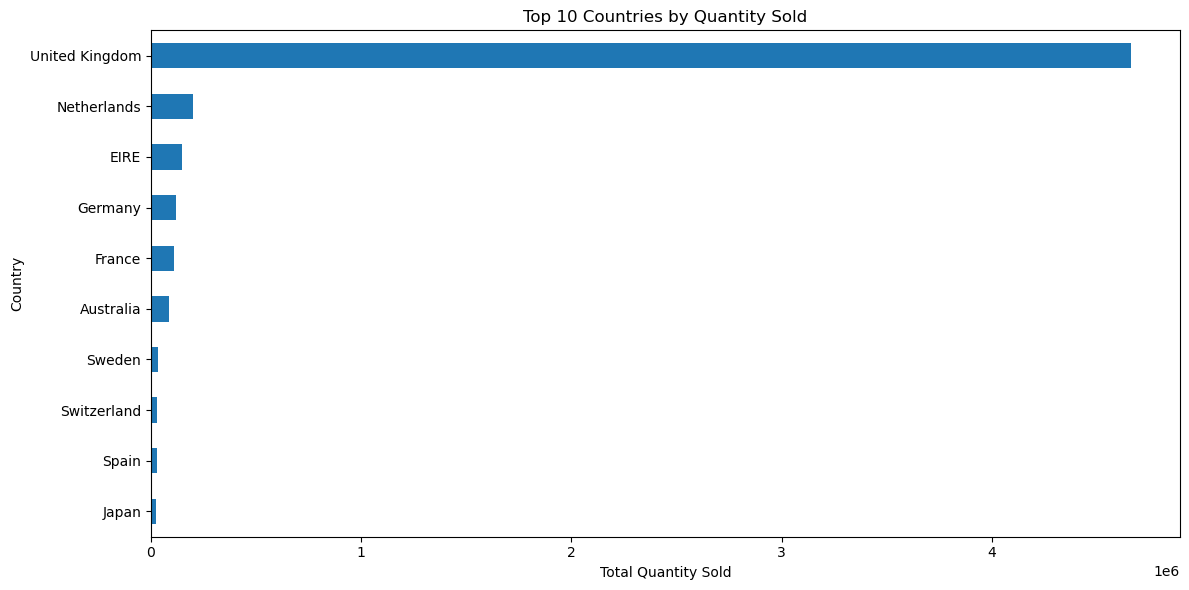

In [63]:
top_country_quantity = country_quantity.head(10)

plt.figure(figsize=(12, 6))
top_country_quantity.sort_values().plot(kind="barh")

plt.title("Top 10 Countries by Quantity Sold")
plt.xlabel("Total Quantity Sold")
plt.ylabel("Country")
plt.tight_layout()
plt.show()

In [65]:
invoice_revenue = (
    sales_df.groupby("InvoiceNo")["Revenue"]
    .sum()
)

average_order_value = invoice_revenue.mean()
total_orders = invoice_revenue.nunique()

print("Total Invoices:", len(invoice_revenue))
print("Average Order Value: £", round(average_order_value, 2))

Total Invoices: 19960
Average Order Value: £ 534.4


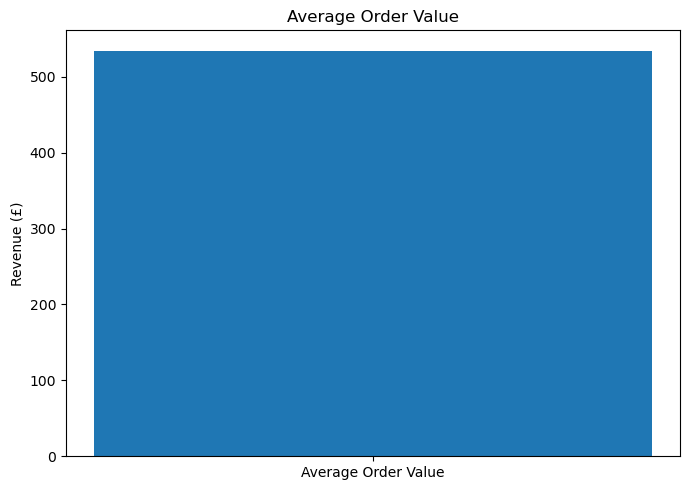

In [67]:
plt.figure(figsize=(7, 5))

plt.bar(
    ["Average Order Value"],
    [average_order_value]
)

plt.title("Average Order Value")
plt.ylabel("Revenue (£)")
plt.tight_layout()
plt.show()

In [69]:
monthly_orders = (
    sales_df.groupby(
        sales_df["InvoiceDate"].dt.to_period("M")
    )["InvoiceNo"]
    .nunique()
)

print("Monthly Order Count:")
print(monthly_orders)

Monthly Order Count:
InvoiceDate
2010-12    1559
2011-01    1086
2011-02    1100
2011-03    1454
2011-04    1246
2011-05    1681
2011-06    1533
2011-07    1475
2011-08    1361
2011-09    1837
2011-10    2040
2011-11    2769
2011-12     819
Freq: M, Name: InvoiceNo, dtype: int64


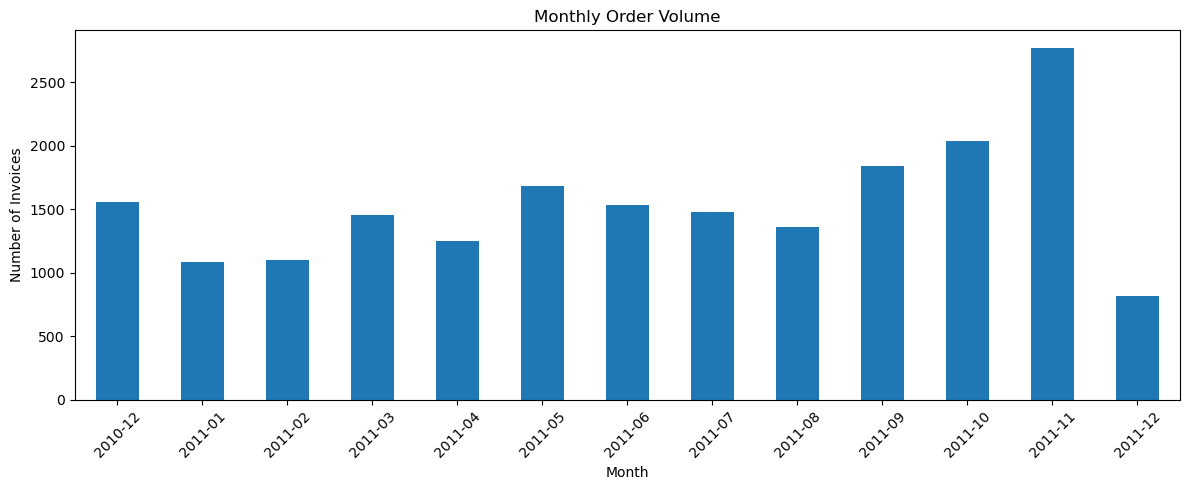

In [71]:
plt.figure(figsize=(12, 5))

monthly_orders.plot(kind="bar")

plt.title("Monthly Order Volume")
plt.xlabel("Month")
plt.ylabel("Number of Invoices")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [73]:
monthly_growth = monthly_sales.pct_change() * 100

print("Monthly Revenue Growth (%):")
print(monthly_growth.round(2))

Monthly Revenue Growth (%):
Month
2010-12      NaN
2011-01   -16.07
2011-02   -24.26
2011-03    37.05
2011-04   -25.06
2011-05    43.27
2011-06    -1.14
2011-07    -5.58
2011-08     5.55
2011-09    39.45
2011-10     9.11
2011-11    30.69
2011-12   -57.68
Freq: M, Name: Revenue, dtype: float64


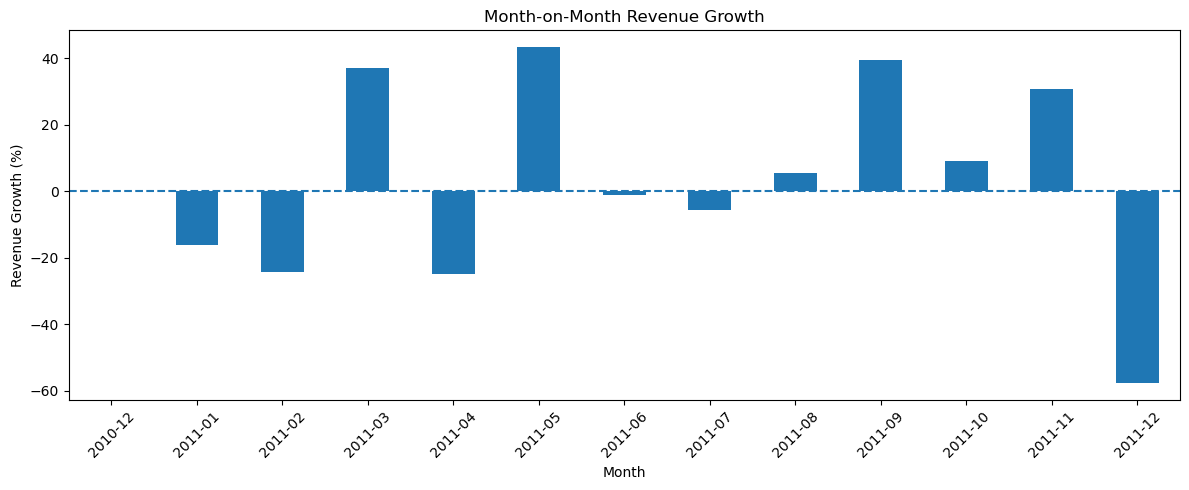

In [75]:
plt.figure(figsize=(12, 5))

monthly_growth.plot(kind="bar")

plt.title("Month-on-Month Revenue Growth")
plt.xlabel("Month")
plt.ylabel("Revenue Growth (%)")
plt.axhline(y=0, linestyle="--")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [78]:
sales_df.to_csv("cleaned_retail_sales.csv", index=False)

print("Cleaned dataset saved successfully!")
print("Number of rows:", sales_df.shape[0])
print("Number of columns:", sales_df.shape[1])

Cleaned dataset saved successfully!
Number of rows: 530104
Number of columns: 12


In [80]:
print("===== RETAIL SALES ANALYSIS SUMMARY =====")

print("Original Dataset Rows:", len(df))
print("Cleaned Sales Rows:", len(sales_df))
print("Unique Customers:", sales_df["CustomerID"].nunique())

print("Total Revenue (£):", round(sales_df["Revenue"].sum(), 2))
print("Total Invoices:", sales_df["InvoiceNo"].nunique())
print("Average Order Value (£):", round(average_order_value, 2))

print("Best Sales Month:", monthly_sales.idxmax())
print("Highest Monthly Revenue (£):", round(monthly_sales.max(), 2))

print("Top Country by Revenue:", country_sales.index[0])
print("Top Product by Purchase Frequency:", product_frequency.index[0])

print("========================================")

===== RETAIL SALES ANALYSIS SUMMARY =====
Original Dataset Rows: 541909
Cleaned Sales Rows: 530104
Unique Customers: 4338
Total Revenue (£): 10666684.54
Total Invoices: 19960
Average Order Value (£): 534.4
Best Sales Month: 2011-11
Highest Monthly Revenue (£): 1509496.33
Top Country by Revenue: United Kingdom
Top Product by Purchase Frequency: WHITE HANGING HEART T-LIGHT HOLDER
